# A4.1 — Estudo de caso: triagem de COVID-19 em radiografias de tórax com augmentation sintética por GAN condicional

**Disciplina:** Visão Computacional com CNNs e Transformers — Projeto da Disciplina
**Autor:** Raphael Alves Carneiro

| Item | Valor |
|---|---|
| Ambiente | Google Colab, GPU T4 (Runtime → Change runtime type → T4 GPU) |
| Memória de GPU | ~4 GB (GAN 128×128 com batch 64; ResNet-18 com batch 32) |
| RAM | ~4 GB |
| Tempo estimado | **~55 a 60 min (medido na T4)**: dados ~1 min, réplica do projeto original <1 min, **duas GANs ~48 min (~24 min cada, incluindo as avaliações de KID/FID)**, 9 treinos de classificador ~5 min |
| Dados | Kaggle `tawsifurrahman/covid19-radiography-database` (COVID-19 Radiography Database) |

**Credenciais do Kaggle.** O notebook usa o cache do Colab ou `kagglehub`; se o Kaggle exigir login, lê `MyDrive/kaggle.json` automaticamente.

**Roteiro**
1. Diagnóstico do projeto original: problemas técnicos e impacto clínico
2. Dados: reprodução do cenário (1.200 imagens, 840/240/120) e um conjunto de teste externo
3. Réplica do projeto original, para medir o problema
4. GAN condicional: versão base e versão estabilizada, com diagnóstico de instabilidade
5. Impacto na recall de COVID-19: treinos com e sem imagens sintéticas
6. Plano de melhoria integrado

## 1. Diagnóstico do projeto original

O cenário: 1.200 radiografias em três classes (Normal 840, Pneumonia 240, COVID-19 120), divisão 80/20 sem estratificação, ResNet-18 **sem pré-treinamento**, SGD com learning rate fixo de 0,01 por 15 épocas, sem augmentation, avaliação só por accuracy global. Resultado reportado: 93% de accuracy de treino e 61% de validação. O time clínico diz que o modelo "ignora casos positivos".

Identifiquei oito problemas. Os cinco primeiros são os mais graves.

| # | Problema técnico | Por que acontece | Impacto clínico esperado |
|---|---|---|---|
| 1 | **Desbalanceamento não tratado** (70% / 20% / 10%) | Com cross-entropy sem pesos, o gradiente é dominado pela classe Normal. O caminho mais barato para reduzir a loss é prever "Normal" na dúvida. | **Falso negativo de COVID-19**: paciente infectado recebe alta, não é isolado e transmite. É exatamente o "ignora casos positivos" relatado. |
| 2 | **Métrica errada: só accuracy global** | Um modelo que chama tudo de Normal já tem 70% de accuracy. Os 61% de validação são compatíveis com recall de COVID perto de zero, e ninguém mediu. | O projeto foi chamado de "promissor" sem nenhuma métrica que refletisse o risco real. Em triagem, a métrica principal é **sensibilidade (recall) da classe positiva**, acompanhada de especificidade. |
| 3 | **Divisão 80/20 sem estratificação e sem conjunto de teste** | Com 120 casos de COVID, a validação deveria ter ~24; sem estratificação, pode ter bem menos (ou mais), por puro acaso. Cada caso vale ~4 pontos de recall. E sem teste separado, o mesmo conjunto serve para escolher e para avaliar o modelo. | Estimativa de desempenho instável e otimista. Não há como saber se o modelo funciona fora daquela amostra. |
| 4 | **ResNet-18 sem pré-treinamento com 1.200 imagens** | São 11 M de parâmetros aprendendo filtros de borda e textura do zero, com ~960 imagens de treino. O gap de 93% para 61% é overfitting clássico. | O modelo decora as imagens de treino, e é justamente na classe rara (COVID) que isso mais pesa, porque ela tem menos exemplos para generalizar. |
| 5 | **Nenhuma augmentation**, e ~96 imagens de COVID no treino | Cada imagem de COVID é vista 15 vezes idêntica. Nada ensina o modelo a ignorar posição, contraste ou exposição. | Baixa robustez a variações de aparelho, técnica radiológica e posicionamento do paciente. Recall cai em hospitais diferentes. |
| 6 | **Otimização sem cuidado**: lr fixo de 0,01 no SGD, 15 épocas, sem schedule, sem early stopping | Com lr alto e fixo, o modelo oscila no fim do treino. E o modelo final é o da última época, não o melhor em validação. | O resultado depende de em que ponto a oscilação parou. Não é reprodutível. |
| 7 | **Confusão por fonte dos dados (shortcut learning)** | Em datasets de COVID montados na pandemia, as imagens de COVID vêm de hospitais e repositórios diferentes das de Normal. O modelo pode aprender marcas de texto, bordas, tipo de aparelho ou posição do paciente em vez da doença. DeGrave et al. (2021, *Nature Machine Intelligence*) mostraram isso em vários modelos publicados. | O modelo parece bom na validação interna e falha no primeiro hospital novo. É o risco mais difícil de ver. |
| 8 | **Sem limiar calibrado nem critério de adoção** | O modelo usa argmax (limiar implícito de ~33% por classe). Em triagem, o limiar deveria ser escolhido para garantir uma sensibilidade mínima, aceitando mais falsos positivos. | Nenhuma decisão clínica pode se apoiar num modelo sem ponto de operação definido. |

Nour & Tariq (2023) chegam à mesma lista de causas em modelos publicados: augmentation insuficiente, desbalanceamento não tratado e métricas inadequadas, com recall de COVID abaixo de 60% em modelos de accuracy alta.

**O que este notebook faz com isso.** Reproduzo o cenário com dados públicos, replico a receita original para medir o problema, corrijo a receita (problemas 1 a 6, e 8 parcialmente) e testo a pergunta central da atividade: **imagens de COVID-19 geradas por uma GAN condicional aumentam a recall da classe minoritária?** O problema 7 não se resolve dentro deste dataset e fica como limitação explícita.

## 2. Dados

In [1]:
!pip -q install kagglehub

import os, json, time, math, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, f1_score
from scipy import linalg

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if AMP else "sem GPU")

SAVE_TO_DRIVE = True
OUT_DIR = Path("/content/outputs/A4")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/PD_VisaoComputacional/A4")
    except Exception as e:
        print("Drive não montado, salvando localmente:", e)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Saídas em:", OUT_DIR)

Device: cuda | Tesla T4
Mounted at /content/drive
Saídas em: /content/drive/MyDrive/PD_VisaoComputacional/A4


In [2]:
import kagglehub

def download_dataset(handle="tawsifurrahman/covid19-radiography-database"):
    try:
        return kagglehub.dataset_download(handle)
    except Exception as e:
        print("Download anônimo falhou, tentando credencial do Drive:", e)
        cred = Path("/content/drive/MyDrive/kaggle.json")
        if not cred.exists():
            raise FileNotFoundError("Coloque o kaggle.json em MyDrive/kaggle.json e rode de novo.")
        k = json.loads(cred.read_text())
        os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = k["username"], k["key"]
        return kagglehub.dataset_download(handle)

DATA_ROOT = Path(download_dataset())
print("Dataset em:", DATA_ROOT)

CLASSES = ["Normal", "Pneumonia", "COVID-19"]
FOLDER2CLS = {"normal": 0, "viral pneumonia": 1, "covid": 2}   # "Lung_Opacity" fica de fora: não faz parte do cenário
files = {0: [], 1: [], 2: []}
for p in DATA_ROOT.rglob("*"):
    if p.suffix.lower() not in {".png", ".jpg", ".jpeg"}: continue
    low = [d.lower() for d in p.parts[:-1]]
    if "masks" in low: continue                                 # o dataset traz máscaras de pulmão: não são radiografias
    cls = next((FOLDER2CLS[d] for d in reversed(low) if d in FOLDER2CLS), None)
    if cls is not None: files[cls].append(p)
for c in files: files[c] = sorted(files[c])
print({CLASSES[c]: len(v) for c, v in files.items()})

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Dataset em: /kaggle/input/covid19-radiography-database
{'Normal': 10192, 'Pneumonia': 1345, 'COVID-19': 3616}


**Reprodução do cenário.** O COVID-19 Radiography Database tem milhares de imagens por classe. Para reproduzir a escassez do projeto original, sorteio exatamente **840 Normal, 240 Pneumonia viral e 120 COVID-19**, as 1.200 imagens "do projeto". É só com elas que treino e seleciono modelos, inclusive a GAN.

**Conjunto de teste externo.** Das imagens que sobram, separo um teste que nenhum modelo vê durante o desenvolvimento: **1.400 Normal, 400 Pneumonia e 200 COVID-19**. Mantenho a mesma proporção 7:2:1 do projeto, para que precisão e accuracy reflitam a prevalência do cenário. Os 200 casos de COVID são o que torna a recall mensurável: com 200 positivos, o erro padrão da recall fica em torno de 3 pontos, contra ~8 pontos com os 24 que uma validação de 20% teria.

As radiografias são carregadas em escala de cinza e reduzidas para **128×128**, a mesma resolução da GAN. Isso é deliberado: se as sintéticas fossem 128 px e as reais 224 px, o classificador poderia aprender "imagem borrada = COVID", um atalho que inflaria a recall no treino e não serviria para nada no teste.

Carregado em 32s | pool (1200, 1, 128, 128) | teste (2000, 1, 128, 128)
Pool: {'Normal': 840, 'Pneumonia': 240, 'COVID-19': 120} | Teste: {'Normal': 1400, 'Pneumonia': 400, 'COVID-19': 200}


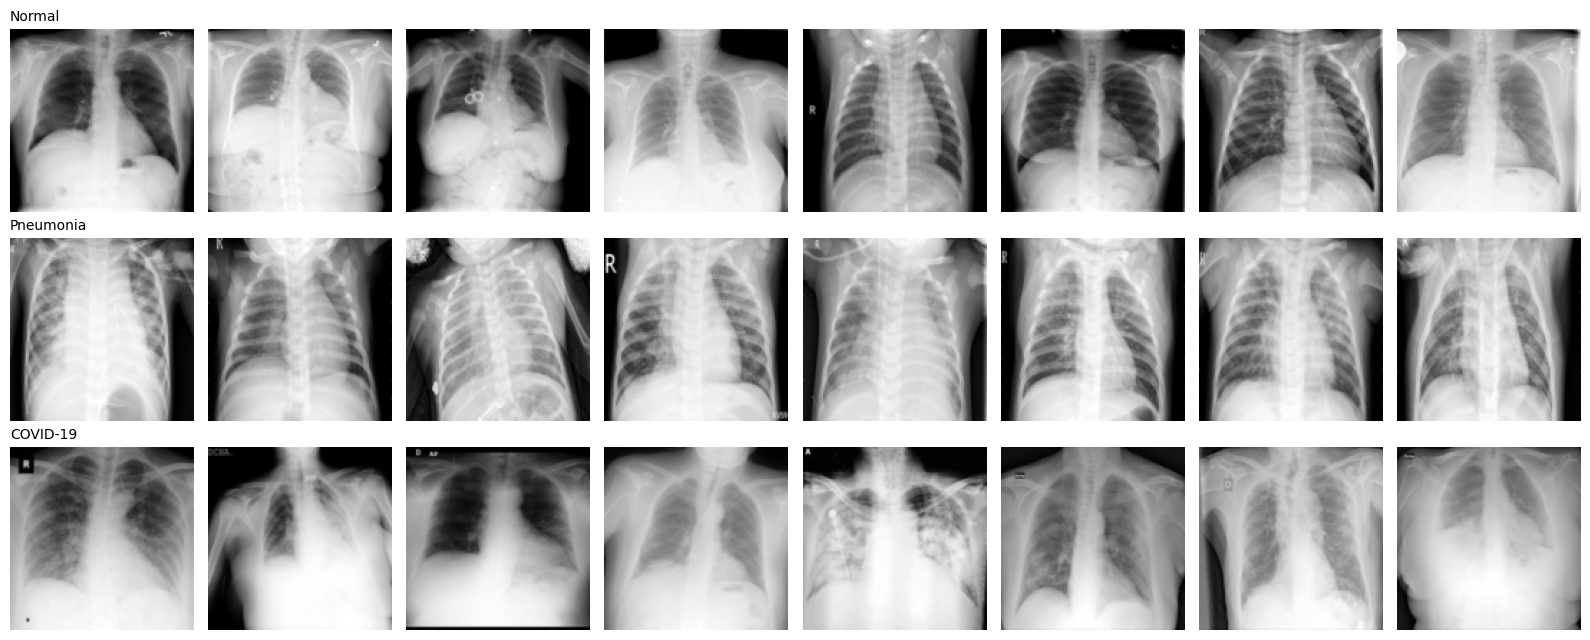

In [3]:
IMG = 128
POOL_N = {0: 840, 1: 240, 2: 120}
TEST_N = {0: 1400, 1: 400, 2: 200}
rng = np.random.RandomState(SEED)

def load_gray(p, size=IMG):
    return np.array(Image.open(p).convert("L").resize((size, size), Image.BILINEAR), dtype=np.uint8)

pool_paths, pool_y, test_paths, test_y = [], [], [], []
for c in range(3):
    idx = rng.permutation(len(files[c]))
    assert len(idx) >= POOL_N[c] + TEST_N[c], f"Poucas imagens em {CLASSES[c]}"
    pool_paths += [files[c][i] for i in idx[:POOL_N[c]]];                   pool_y += [c] * POOL_N[c]
    test_paths += [files[c][i] for i in idx[POOL_N[c]:POOL_N[c] + TEST_N[c]]]; test_y += [c] * TEST_N[c]

t0 = time.time()
X_pool = torch.from_numpy(np.stack([load_gray(p) for p in pool_paths]))[:, None]   # (1200, 1, 128, 128) uint8
X_test = torch.from_numpy(np.stack([load_gray(p) for p in test_paths]))[:, None]
y_pool, y_test = torch.tensor(pool_y), torch.tensor(test_y)
print(f"Carregado em {time.time()-t0:.0f}s | pool {tuple(X_pool.shape)} | teste {tuple(X_test.shape)}")
print("Pool:", {CLASSES[c]: int((y_pool == c).sum()) for c in range(3)}, "| Teste:", {CLASSES[c]: int((y_test == c).sum()) for c in range(3)})

fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for c in range(3):
    for j, i in enumerate(torch.where(y_pool == c)[0][:8]):
        axes[c, j].imshow(X_pool[i, 0], cmap="gray"); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASSES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_amostras_reais.png", dpi=110); plt.show()

In [4]:
# Divisão estratificada do pool para a receita corrigida: 85% treino / 15% validação (seleção de modelo).
idx = np.arange(len(y_pool))
tr_idx, va_idx = train_test_split(idx, test_size=0.15, stratify=y_pool.numpy(), random_state=SEED)
X_tr, y_tr, X_va, y_va = X_pool[tr_idx], y_pool[tr_idx], X_pool[va_idx], y_pool[va_idx]
print("Treino:", {CLASSES[c]: int((y_tr == c).sum()) for c in range(3)}, "| Validação:", {CLASSES[c]: int((y_va == c).sum()) for c in range(3)})

# Divisão do projeto original: 80/20 aleatória, SEM estratificação. Mostro quantos COVID caem na validação por acaso.
orig_tr, orig_va = train_test_split(idx, test_size=0.20, random_state=7)
covid_in_val = [(y_pool[train_test_split(idx, test_size=0.20, random_state=s)[1]] == 2).sum().item() for s in range(1000)]
print(f"Divisão original (semente usada): {(y_pool[orig_va] == 2).sum().item()} COVID na validação")
print(f"Em 1.000 divisões aleatórias, COVID na validação variou de {min(covid_in_val)} a {max(covid_in_val)} "
      f"(esperado 24) — cada caso vale {100/24:.1f} pontos de recall")

Treino: {'Normal': 714, 'Pneumonia': 204, 'COVID-19': 102} | Validação: {'Normal': 126, 'Pneumonia': 36, 'COVID-19': 18}
Divisão original (semente usada): 24 COVID na validação
Em 1.000 divisões aleatórias, COVID na validação variou de 13 a 35 (esperado 24) — cada caso vale 4.2 pontos de recall


## 3. Classificador: réplica do projeto original e receita corrigida

As duas receitas usam a **mesma arquitetura (ResNet-18)**, para que as diferenças venham do processo de treino e não do modelo:

| | Projeto original (réplica) | Receita corrigida |
|---|---|---|
| Pesos iniciais | aleatórios | ImageNet (transfer learning) |
| Divisão | 80/20 aleatória, sem estratificação | 85/15 estratificada + **teste externo de 2.000 imagens** |
| Otimizador | SGD, lr fixo 0,01, momentum 0,9 (o enunciado não especifica o momentum) | AdamW, lr 3e-4, weight decay 1e-4, cosine schedule |
| Épocas / seleção | 15, modelo da última época | 15, melhor época pela **balanced accuracy** de validação |
| Augmentation | nenhuma | rotação ±7°, translação ±5%, escala 0,95–1,08, brilho/contraste ±10% |
| Métricas | accuracy global | recall, precisão e F1 por classe, balanced accuracy, AUC de COVID, matriz de confusão |

**Sem flip horizontal, de propósito.** Numa radiografia PA o coração fica do lado esquerdo do paciente; espelhar a imagem cria uma anatomia que praticamente não existe (dextrocardia é rara). As augmentations escolhidas simulam o que de fato varia entre exames: posicionamento do paciente, enquadramento e exposição.

A radiografia em escala de cinza é replicada nos 3 canais e normalizada com as estatísticas do ImageNet, para aproveitar os pesos pré-treinados.

In [5]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

class XrayResNet(nn.Module):
    def __init__(self, pretrained):
        super().__init__()
        self.m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        self.m.fc = nn.Linear(512, 3)
        self.register_buffer("mean", IMAGENET_MEAN); self.register_buffer("std", IMAGENET_STD)
    def forward(self, x):                        # x: (B, 1, H, W) em [0, 1]
        return self.m((x.repeat(1, 3, 1, 1) - self.mean) / self.std)

class BrightnessContrast:
    def __init__(self, b=0.10, c=0.10): self.b, self.c = b, c
    def __call__(self, x):
        m = x.mean()
        x = (x - m) * (1 + (torch.rand(1).item() * 2 - 1) * self.c) + m
        return (x + (torch.rand(1).item() * 2 - 1) * self.b).clamp(0, 1)

AUG = transforms.Compose([
    transforms.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.08)),
    BrightnessContrast(0.10, 0.10),
])

class XrayDS(Dataset):
    def __init__(self, X, y, aug=None): self.X, self.y, self.aug = X, y, aug
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].float() / 255.0
        return (self.aug(x) if self.aug else x), int(self.y[i])

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval(); probs = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].float().div(255).to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=AMP):
            probs.append(model(x).float().softmax(1).cpu())
    return torch.cat(probs)

def metrics(y, probs):
    y = np.asarray(y); p = probs.argmax(1).numpy()
    cm = confusion_matrix(y, p, labels=range(3))
    rec = cm.diagonal() / cm.sum(1); prec = cm.diagonal() / np.maximum(cm.sum(0), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return {"accuracy": (p == y).mean(), "balanced_acc": rec.mean(), "macro_f1": f1.mean(),
            "recall_normal": rec[0], "recall_pneumonia": rec[1], "recall_covid": rec[2],
            "precision_covid": prec[2], "f1_covid": f1[2],
            "auc_covid": roc_auc_score((y == 2).astype(int), probs[:, 2].numpy()), "cm": cm}

def train_classifier(X_train, y_train, X_val, y_val, pretrained=True, optimizer="adamw", lr=3e-4, epochs=15,
                     augment=True, balanced_sampler=False, select_best=True, seed=0, bs=32, tag=""):
    seed_everything(seed)
    model = XrayResNet(pretrained).to(DEVICE)
    ds = XrayDS(X_train, y_train, AUG if augment else None)
    g = torch.Generator().manual_seed(seed)
    if balanced_sampler:
        w = (1.0 / torch.bincount(y_train, minlength=3).float())[y_train]
        loader = DataLoader(ds, batch_size=bs, sampler=WeightedRandomSampler(w, len(w), replacement=True, generator=g), num_workers=2)
    else:
        loader = DataLoader(ds, batch_size=bs, shuffle=True, generator=g, num_workers=2)
    if optimizer == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9); sched = None
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loader))
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, best_state = [], -1e9, None
    for ep in range(1, epochs + 1):
        model.train(); tl = tc = tn = 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE.type, enabled=AMP):
                logits = model(x); loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        pv = predict(model, X_val); mv = metrics(y_val, pv)
        vloss = F.nll_loss(pv.clamp_min(1e-8).log(), y_val).item()
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vloss, val_acc=mv["accuracy"],
                         val_bal_acc=mv["balanced_acc"], val_recall_covid=mv["recall_covid"]))
        score = mv["balanced_acc"] - 1e-3 * vloss
        if select_best and score > best:
            best, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if select_best: model.load_state_dict(best_state)
    h = pd.DataFrame(hist)
    print(f"[{tag}] seed {seed} | treino acc {h.train_acc.iloc[-1]:.3f} | val acc {h.val_acc.iloc[-1]:.3f} | "
          f"val bal.acc (melhor) {h.val_bal_acc.max():.3f}")
    return model, h

[réplica original] seed 0 | treino acc 0.983 | val acc 0.896 | val bal.acc (melhor) 0.850
Tempo: 15s

O que o grupo original teria reportado -> treino: 98.3% | validação: 89.6%
O que ninguém mediu (validação) -> recall COVID: 37.5% | balanced acc: 73.0%
No teste externo -> accuracy 88.6% | recall COVID 26.0% | recall Pneumonia 93.2% | recall Normal 96.3%


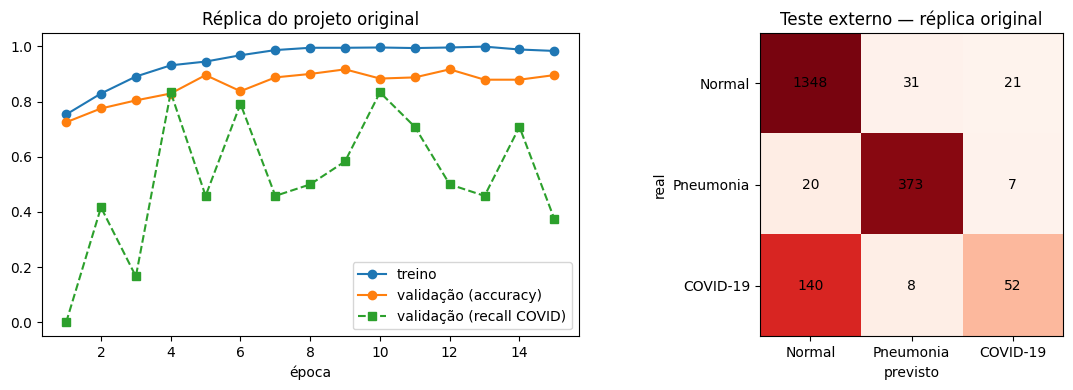

In [6]:
# Réplica do projeto original: pesos aleatórios, SGD lr 0,01 fixo, 15 épocas, sem augmentation, 80/20 sem estratificação, última época.
t0 = time.time()
orig_model, orig_hist = train_classifier(X_pool[orig_tr], y_pool[orig_tr], X_pool[orig_va], y_pool[orig_va],
                                         pretrained=False, optimizer="sgd", lr=0.01, epochs=15, augment=False,
                                         select_best=False, seed=0, tag="réplica original")
m_orig_val = metrics(y_pool[orig_va], predict(orig_model, X_pool[orig_va]))
m_orig_test = metrics(y_test, predict(orig_model, X_test))
print(f"Tempo: {time.time()-t0:.0f}s")
print(f"\nO que o grupo original teria reportado -> treino: {orig_hist.train_acc.iloc[-1]:.1%} | validação: {m_orig_val['accuracy']:.1%}")
print(f"O que ninguém mediu (validação) -> recall COVID: {m_orig_val['recall_covid']:.1%} | balanced acc: {m_orig_val['balanced_acc']:.1%}")
print(f"No teste externo -> accuracy {m_orig_test['accuracy']:.1%} | recall COVID {m_orig_test['recall_covid']:.1%} | "
      f"recall Pneumonia {m_orig_test['recall_pneumonia']:.1%} | recall Normal {m_orig_test['recall_normal']:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(orig_hist.epoch, orig_hist.train_acc, "o-", label="treino"); ax[0].plot(orig_hist.epoch, orig_hist.val_acc, "o-", label="validação (accuracy)")
ax[0].plot(orig_hist.epoch, orig_hist.val_recall_covid, "s--", label="validação (recall COVID)")
ax[0].set_title("Réplica do projeto original"); ax[0].set_xlabel("época"); ax[0].legend()
cm = m_orig_test["cm"]; ax[1].imshow(cm / cm.sum(1, keepdims=True), cmap="Reds", vmin=0, vmax=1)
for i in range(3):
    for j in range(3): ax[1].text(j, i, cm[i, j], ha="center", va="center")
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(CLASSES); ax[1].set_yticks(range(3)); ax[1].set_yticklabels(CLASSES)
ax[1].set_xlabel("previsto"); ax[1].set_ylabel("real"); ax[1].set_title("Teste externo — réplica original")
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_replica_original.png", dpi=140); plt.show()


### Leitura da réplica

**O que o grupo teria reportado:** 98,3% de accuracy de treino e 89,6% de validação. Na minha réplica o gap é menor que o 93%/61% do enunciado, provavelmente porque este repositório tem sinais de fonte que facilitam a tarefa (problema 7, discutido na seção 4). O padrão, porém, é o mesmo.

**O que ninguém mediu:** a recall de COVID na validação era de **37,5%** (9 de 24). No teste externo, a réplica tem **88,6% de accuracy e 26% de recall de COVID**: dos 200 casos de COVID, **140 foram classificados como Normal**, 8 como Pneumonia e só 52 como COVID. É literalmente o "ignora casos positivos" do time clínico, e bate com Nour & Tariq (2023), que encontraram recall de COVID abaixo de 60% em modelos de accuracy alta.

Os erros vão quase todos para **Normal**, e não para Pneumonia. Com 70% dos exemplos de treino sendo Normal, na dúvida o modelo escolhe a classe majoritária (problema 1). Clinicamente, é o pior erro possível: o paciente com COVID recebe o rótulo de saudável.

**O learning rate fixo aparece na curva.** A recall de COVID na validação oscila entre 0% e 83% de uma época para a outra, enquanto a accuracy de validação fica praticamente estável entre 84% e 92%. A accuracy global esconde que o comportamento do modelo na classe que importa muda completamente de época para época, e o modelo entregue é o da última época, com 37,5% (problemas 2 e 6).

**Divisão sem estratificação.** Em 1.000 sorteios da divisão 80/20, o número de casos de COVID na validação variou de **13 a 35**. Com 13 casos, cada erro vale 7,7 pontos de recall (problema 3).


## 4. GAN condicional para gerar radiografias de COVID-19

**Por que GAN condicional e não CycleGAN.** A CycleGAN traduz imagens entre domínios (por exemplo, Normal → COVID), preservando a anatomia da imagem de origem. Parece atraente, mas com ~100 imagens de COVID o risco é ela aprender só uma "textura de COVID" colada sobre pulmões normais, e com 840 imagens Normal servindo de base a diversidade viria quase toda da classe errada. A **GAN condicional** aprende as três classes juntas: a anatomia comum (costelas, silhueta cardíaca, diafragma) vem das ~1.000 imagens de treino, e o rótulo ensina o que muda em cada doença. É o jeito mais eficiente de usar tão pouco dado de COVID. Ela também é mais barata na T4: um gerador e um discriminador, contra dois de cada na CycleGAN.

**Arquitetura (DCGAN condicional, 128×128, escala de cinza).**
- **Gerador:** ruído $z \in \mathbb{R}^{128}$ concatenado com um embedding aprendido da classe, seguido de 6 convoluções transpostas (4 → 8 → … → 128 px) com BatchNorm e ReLU, e saída `tanh`.
- **Discriminador de projeção** (Miyato & Koyama, 2018): 5 convoluções com stride 2, soma global das features $h$ e saída $\psi(h) + \langle \text{embed}(y), h \rangle$. O rótulo entra como produto interno com as features, e não concatenado na entrada, o que dá um sinal de classe mais forte e estável.
- **Amostragem balanceada por classe** no treino da GAN: cada batch tem as três classes em proporções iguais. Sem isso, a GAN veria COVID em só 10% dos batches.

**Loop adversarial.** A cada passo: (1) o discriminador recebe um batch real e um falso (gerado com `fake.detach()`, para que o gradiente não chegue ao gerador) e atualiza os pesos para separá-los; (2) o gerador gera um novo batch e atualiza os pesos para que o discriminador classifique esse batch como real, com o gradiente atravessando o discriminador congelado.

**Duas versões, para diagnosticar e mitigar instabilidade:**

| | **v1 — base (DCGAN clássica)** | **v2 — estabilizada** |
|---|---|---|
| Loss | BCE não saturante | **hinge** |
| Normalização no D | BatchNorm | **spectral normalization** (restringe a constante de Lipschitz do D) |
| Augmentation no D | nenhuma | **DiffAugment** (Zhao et al., 2020): brilho, contraste, translação e cutout aplicados igualmente a reais e falsas |
| Learning rates | 2e-4 / 2e-4 | **TTUR**: D 4e-4, G 1e-4 |
| Pesos do gerador | último passo | **média móvel exponencial (EMA)** dos pesos |

**O que eu espero da v1, e por quê.** Com ~1.000 imagens, o discriminador consegue *decorar* o conjunto de treino. Quando isso acontece, ele passa a rejeitar qualquer coisa que não seja exatamente uma das imagens vistas, o gradiente para o gerador perde informação e o gerador tende a colapsar em poucas saídas que ainda enganam o D (**mode collapse**) ou a oscilar sem convergir. Instrumentei o treino para medir isso diretamente:

1. **Gap de overfitting do discriminador:** a saída média do D em imagens reais de *treino* menos a saída em imagens reais de *validação*, que ele nunca viu. Se o D generaliza, o gap fica perto de zero; se decora, cresce.
2. **KID e FID por classe:** distância entre as distribuições de features (Inception-v3) de imagens reais e geradas. O KID é a métrica principal porque é não enviesado para amostras pequenas; o FID com ~100 imagens de COVID é instável, então só o uso de forma comparativa.
3. **Razão de diversidade:** distância média entre pares de imagens geradas dividida pela mesma distância entre imagens reais da classe. Perto de 1 é saudável; bem abaixo de 1 indica mode collapse.

In [7]:
Z_DIM, NC, GCH, DCH = 128, 3, 48, 48

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Embedding(NC, Z_DIM)
        def up(i, o): return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(
            nn.ConvTranspose2d(2 * Z_DIM, GCH * 16, 4, 1, 0, bias=False), nn.BatchNorm2d(GCH * 16), nn.ReLU(True),  # 4x4
            *up(GCH * 16, GCH * 8), *up(GCH * 8, GCH * 4), *up(GCH * 4, GCH * 2), *up(GCH * 2, GCH),              # 64x64
            nn.ConvTranspose2d(GCH, 1, 4, 2, 1), nn.Tanh())                                                        # 128x128
    def forward(self, z, y):
        return self.net(torch.cat([z, self.embed(y)], 1)[:, :, None, None])

class Discriminator(nn.Module):
    def __init__(self, spectral=False, batchnorm=True):
        super().__init__()
        SN = nn.utils.spectral_norm if spectral else (lambda m: m)
        chans = [1, DCH, DCH * 2, DCH * 4, DCH * 8, DCH * 16]
        layers = []
        for k, (i, o) in enumerate(zip(chans[:-1], chans[1:])):
            layers.append(SN(nn.Conv2d(i, o, 4, 2, 1)))
            if batchnorm and k > 0: layers.append(nn.BatchNorm2d(o))
            layers.append(nn.LeakyReLU(0.2, True))
        self.features = nn.Sequential(*layers)                 # 128 -> 4
        self.out = SN(nn.Linear(chans[-1], 1))
        self.embed = SN(nn.Embedding(NC, chans[-1]))
    def forward(self, x, y):
        h = self.features(x).sum(dim=[2, 3])                 # soma global
        return self.out(h).squeeze(1) + (self.embed(y) * h).sum(1)   # projeção condicional

def dcgan_init(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        w = getattr(m, "weight_orig", m.weight); nn.init.normal_(w, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

# --- DiffAugment (Zhao et al., 2020), versão para 1 canal: diferenciável, aplicada a reais e falsas ---
def diff_augment(x):
    B = x.size(0); dev = x.device
    x = x + (torch.rand(B, 1, 1, 1, device=dev) - 0.5) * 0.5                                     # brilho
    m = x.mean(dim=[1, 2, 3], keepdim=True); x = (x - m) * (torch.rand(B, 1, 1, 1, device=dev) * 0.6 + 0.7) + m   # contraste
    # translação de até 1/8 da imagem (com padding zero)
    H, W = x.shape[2:]; s = H // 8
    tx = torch.randint(-s, s + 1, (B, 1, 1), device=dev); ty = torch.randint(-s, s + 1, (B, 1, 1), device=dev)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=dev), torch.arange(H, device=dev), torch.arange(W, device=dev), indexing="ij")
    gx = (gx + tx + 1).clamp(0, H + 1); gy = (gy + ty + 1).clamp(0, W + 1)
    x = F.pad(x, [1, 1, 1, 1]).permute(0, 2, 3, 1)[gb, gx, gy].permute(0, 3, 1, 2)
    # cutout de 30% do lado
    cs = int(H * 0.3)
    ox = torch.randint(0, H - cs + 1, (B, 1, 1), device=dev); oy = torch.randint(0, W - cs + 1, (B, 1, 1), device=dev)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=dev), torch.arange(cs, device=dev), torch.arange(cs, device=dev), indexing="ij")
    mask = torch.ones(B, H, W, device=dev); mask[gb, gx + ox, gy + oy] = 0
    return x * mask[:, None]

G_tmp, D_tmp = Generator(), Discriminator(spectral=True, batchnorm=False)
print(f"Gerador: {sum(p.numel() for p in G_tmp.parameters())/1e6:.1f} M parâmetros | "
      f"Discriminador: {sum(p.numel() for p in D_tmp.parameters())/1e6:.1f} M parâmetros")
with torch.no_grad():
    assert G_tmp(torch.randn(2, Z_DIM), torch.tensor([0, 2])).shape == (2, 1, 128, 128)
    assert D_tmp(torch.randn(2, 1, 128, 128), torch.tensor([0, 2])).shape == (2,)
    assert diff_augment(torch.randn(4, 1, 128, 128)).shape == (4, 1, 128, 128)
del G_tmp, D_tmp
print("✓ formas de G, D e DiffAugment")

Gerador: 9.4 M parâmetros | Discriminador: 6.3 M parâmetros
✓ formas de G, D e DiffAugment


In [8]:
# Extrator de features para KID/FID/diversidade: Inception-v3 do torchvision (ImageNet), camada de pooling (2048-d).
# Os valores não são comparáveis com FIDs publicados (outra implementação), só entre as versões deste notebook.
inception = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
inception.fc = nn.Identity(); inception = inception.to(DEVICE).eval()

@torch.no_grad()
def incep_features(X01, bs=100):              # X01: (N, 1, H, W) em [0, 1]
    feats = []
    for i in range(0, len(X01), bs):
        x = X01[i:i + bs].to(DEVICE).float()
        x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
        x = (x - IMAGENET_MEAN.to(DEVICE)) / IMAGENET_STD.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=AMP):
            feats.append(inception(x).float().cpu())
    return torch.cat(feats).double()

def fid(f1, f2):
    try:
        mu1, mu2 = f1.mean(0).numpy(), f2.mean(0).numpy()
        s1, s2 = np.cov(f1.numpy(), rowvar=False), np.cov(f2.numpy(), rowvar=False)
        covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
        return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))
    except Exception:
        return float("nan")

def kid(f1, f2, n_subsets=50, subset=None, seed=0):
    # Kernel Inception Distance (Bińkowski et al., 2018): MMD² não enviesado com kernel polinomial cúbico. Reporto ×1000.
    g = np.random.RandomState(seed); d = f1.shape[1]
    m = subset or min(len(f1), len(f2), 100); vals = []
    for _ in range(n_subsets):
        x = f1[g.choice(len(f1), m, replace=False)]; y = f2[g.choice(len(f2), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3; kyy = (y @ y.T / d + 1) ** 3; kxy = (x @ y.T / d + 1) ** 3
        vals.append(((kxx.sum() - kxx.diag().sum()) / (m * (m - 1)) + (kyy.sum() - kyy.diag().sum()) / (m * (m - 1))
                     - 2 * kxy.mean()).item())
    return 1000 * float(np.mean(vals))

def diversity(f, n=300, seed=0):
    g = np.random.RandomState(seed); f = f[g.choice(len(f), min(n, len(f)), replace=False)]
    f = F.normalize(f, dim=1); s = f @ f.T
    return float((1 - s)[~torch.eye(len(f), dtype=bool)].mean())

REAL_FEATS = {c: incep_features(X_tr[y_tr == c].float() / 255) for c in range(3)}
REAL_DIV = {c: diversity(REAL_FEATS[c]) for c in range(3)}
print("Features reais (treino):", {CLASSES[c]: tuple(REAL_FEATS[c].shape) for c in range(3)})
print("Diversidade real por classe:", {CLASSES[c]: round(v, 4) for c, v in REAL_DIV.items()})

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 148MB/s] 


Features reais (treino): {'Normal': (714, 2048), 'Pneumonia': (204, 2048), 'COVID-19': (102, 2048)}
Diversidade real por classe: {'Normal': 0.2269, 'Pneumonia': 0.2293, 'COVID-19': 0.2807}


In [9]:
GAN_STEPS, GAN_BS, EVAL_EVERY, N_EVAL = 4000, 64, 1000, 200
X_tr_gan = (X_tr.float() / 255 * 2 - 1)              # [-1, 1] para o tanh
X_va_gan = (X_va.float() / 255 * 2 - 1)
cls_idx = [torch.where(y_tr == c)[0] for c in range(3)]

def sample_real(bs, gen):
    y = torch.randint(0, NC, (bs,), generator=gen)                 # classes balanceadas
    idx = torch.empty(bs, dtype=torch.long)
    for c in range(NC):
        m = y == c
        idx[m] = cls_idx[c][torch.randint(len(cls_idx[c]), (int(m.sum()),), generator=gen)]
    return X_tr_gan[idx].to(DEVICE), y.to(DEVICE)

@torch.no_grad()
def generate(G, n, cls, bs=100, seed=0):
    was_training = G.training
    G.eval(); g = torch.Generator(device=DEVICE).manual_seed(seed); out = []
    for i in range(0, n, bs):
        k = min(bs, n - i)
        z = torch.randn(k, Z_DIM, device=DEVICE, generator=g)
        out.append(G(z, torch.full((k,), cls, device=DEVICE, dtype=torch.long)).cpu())
    G.train(was_training)
    return (torch.cat(out) + 1) / 2                                  # [0, 1]

def train_gan(version):
    stable = version == "v2"
    seed_everything(123)
    G, D = Generator().to(DEVICE), Discriminator(spectral=stable, batchnorm=not stable).to(DEVICE)
    G.apply(dcgan_init); D.apply(dcgan_init)
    optG = torch.optim.Adam(G.parameters(), lr=1e-4 if stable else 2e-4, betas=(0.0 if stable else 0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=4e-4 if stable else 2e-4, betas=(0.0 if stable else 0.5, 0.999))
    G_ema = copy.deepcopy(G).eval() if stable else None
    aug = diff_augment if stable else (lambda x: x)
    gen = torch.Generator().manual_seed(0)
    fixed_z = torch.randn(8 * NC, Z_DIM, device=DEVICE); fixed_y = torch.arange(NC, device=DEVICE).repeat_interleave(8)
    log, evals, snaps, ckpts = [], [], {}, {}
    t0 = time.time()
    for step in range(1, GAN_STEPS + 1):
        real, y = sample_real(GAN_BS, gen)
        z = torch.randn(GAN_BS, Z_DIM, device=DEVICE)
        fake = G(z, y)
        d_real, d_fake = D(aug(real), y), D(aug(fake.detach()), y)          # detach: o passo do D não atualiza o G
        if stable:
            d_loss = F.relu(1 - d_real).mean() + F.relu(1 + d_fake).mean()
        else:
            d_loss = F.binary_cross_entropy_with_logits(d_real, torch.ones_like(d_real)) + \
                     F.binary_cross_entropy_with_logits(d_fake, torch.zeros_like(d_fake))
        optD.zero_grad(set_to_none=True); d_loss.backward(); optD.step()

        z = torch.randn(GAN_BS, Z_DIM, device=DEVICE)
        g_out = D(aug(G(z, y)), y)                                             # gradiente atravessa o D até o G
        g_loss = -g_out.mean() if stable else F.binary_cross_entropy_with_logits(g_out, torch.ones_like(g_out))
        optG.zero_grad(set_to_none=True); g_loss.backward(); optG.step()
        if stable:
            with torch.no_grad():
                for pe, p in zip(G_ema.parameters(), G.parameters()): pe.lerp_(p, 1 - 0.999)
                for be, b in zip(G_ema.buffers(), G.buffers()): be.copy_(b)

        if step % 50 == 0:
            with torch.no_grad():
                D.eval()
                vi = torch.randint(len(X_va_gan), (64,), generator=gen)
                ti = torch.randint(len(X_tr_gan), (64,), generator=gen)
                d_tr = D(X_tr_gan[ti].to(DEVICE), y_tr[ti].to(DEVICE)).mean().item()
                d_va = D(X_va_gan[vi].to(DEVICE), y_va[vi].to(DEVICE)).mean().item()
                D.train()
            log.append(dict(step=step, d_loss=d_loss.item(), g_loss=g_loss.item(), d_real=d_real.mean().item(),
                            d_fake=d_fake.mean().item(), d_train_real=d_tr, d_val_real=d_va, overfit_gap=d_tr - d_va))
        if step % EVAL_EVERY == 0:
            Gs = G_ema if stable else G
            row = {"step": step}
            for c in range(NC):
                fe = incep_features(generate(Gs, N_EVAL, c, seed=c))
                row[f"KID {CLASSES[c]}"] = kid(REAL_FEATS[c], fe)
                row[f"FID {CLASSES[c]}"] = fid(REAL_FEATS[c], fe)
                row[f"diversidade {CLASSES[c]}"] = diversity(fe) / REAL_DIV[c]
            evals.append(row)
            with torch.no_grad():
                was = Gs.training; Gs.eval(); snaps[step] = ((Gs(fixed_z, fixed_y) + 1) / 2).cpu(); Gs.train(was)
            ckpts[step] = copy.deepcopy(Gs.state_dict())
            print(f"[{version}] passo {step} | {time.time()-t0:.0f}s | D {d_loss.item():.3f} G {g_loss.item():.3f} | "
                  f"gap overfit D {(log[-1]['overfit_gap'] if log else float('nan')):.2f} | KID COVID {row['KID COVID-19']:.1f} | "
                  f"div. COVID {row['diversidade COVID-19']:.2f}")
    return dict(G=G_ema if stable else G, log=pd.DataFrame(log), evals=pd.DataFrame(evals), snaps=snaps, ckpts=ckpts,
                time=time.time() - t0)

gan = {}
for v in ["v1", "v2"]:
    gan[v] = train_gan(v)
    gan[v]["log"].to_csv(OUT_DIR / f"a4_gan_{v}_log.csv", index=False); gan[v]["evals"].to_csv(OUT_DIR / f"a4_gan_{v}_evals.csv", index=False)
    print(f"GAN {v}: {gan[v]['time']/60:.1f} min\n")

/tmp/ipykernel_649/2794260690.py:21: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
/tmp/ipykernel_649/2794260690.py:21: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)


[v1] passo 1000 | 345s | D 0.010 G 11.425 | gap overfit D -1.92 | KID COVID 557.2 | div. COVID 0.07
[v1] passo 2000 | 697s | D 0.007 G 41.143 | gap overfit D 1.26 | KID COVID 526.1 | div. COVID 0.03
[v1] passo 3000 | 1065s | D 0.057 G 12.452 | gap overfit D 13.61 | KID COVID 673.9 | div. COVID 0.03
[v1] passo 4000 | 1417s | D 0.303 G 5.478 | gap overfit D -3.23 | KID COVID 589.9 | div. COVID 0.04
GAN v1: 23.6 min

[v2] passo 1000 | 355s | D 1.830 G 0.604 | gap overfit D 0.02 | KID COVID 600.1 | div. COVID 0.03
[v2] passo 2000 | 714s | D 1.573 G 0.458 | gap overfit D -0.01 | KID COVID 488.9 | div. COVID 0.51
[v2] passo 3000 | 1075s | D 1.592 G 0.465 | gap overfit D 0.04 | KID COVID 353.6 | div. COVID 0.70
[v2] passo 4000 | 1438s | D 1.894 G 0.423 | gap overfit D -0.04 | KID COVID 245.3 | div. COVID 0.71
GAN v2: 24.0 min



### 4.1 Diagnóstico de instabilidade: v1 vs. v2

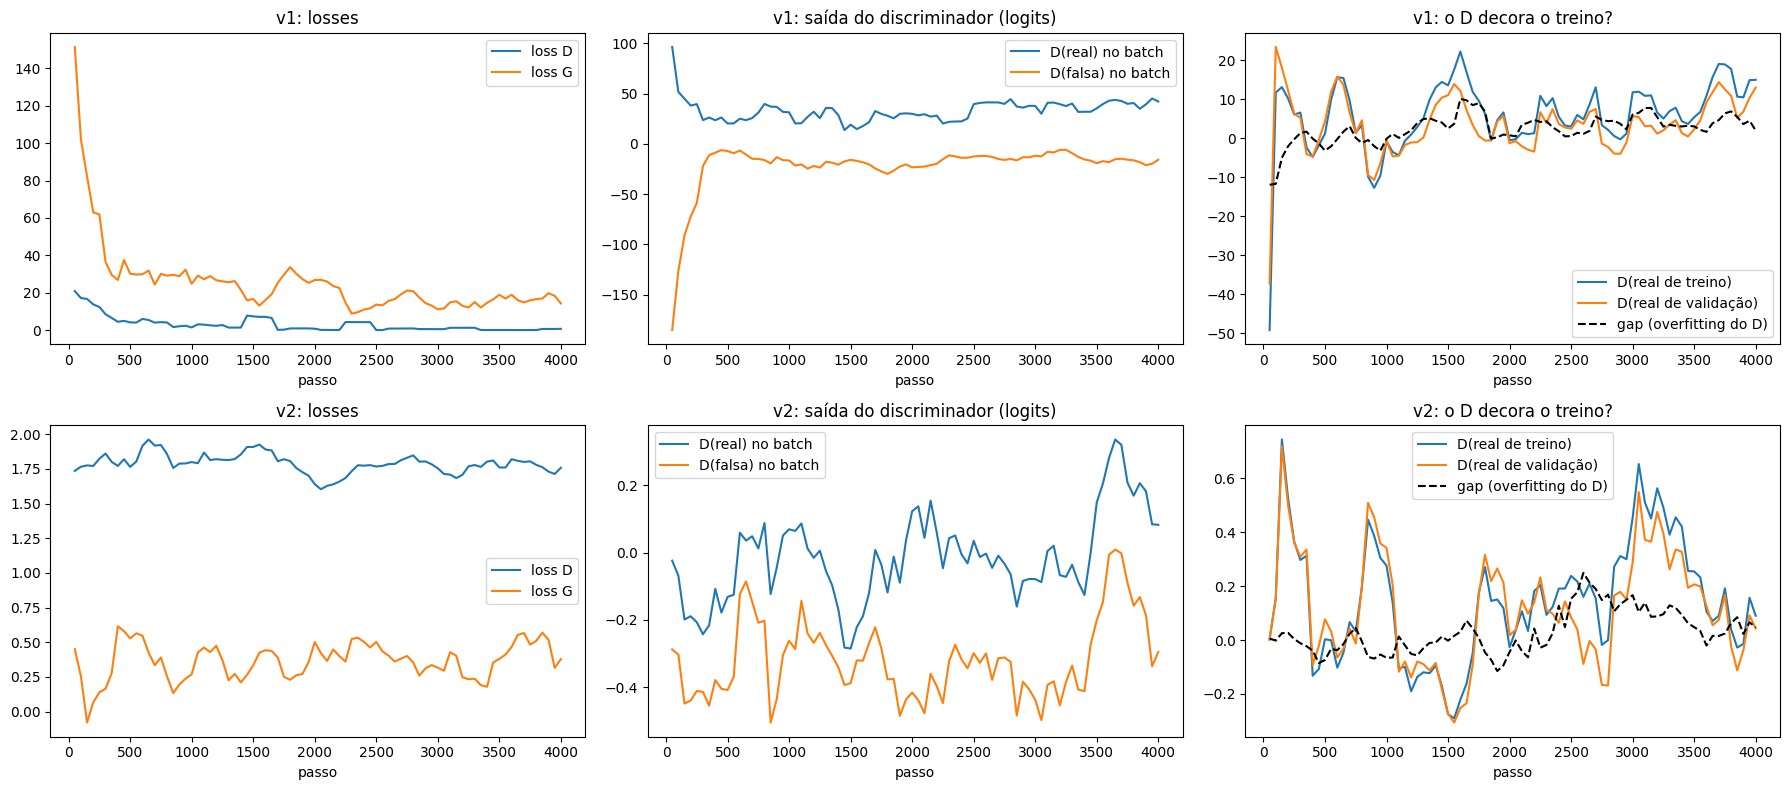

KID Normal  FID Normal  diversidade Normal  KID Pneumonia  \
versão step                                                              
v1     1000     684.398     458.204               0.108        746.783   
       2000     706.966     466.919               0.037        644.209   
       3000     580.445     412.332               0.043        739.841   
       4000     693.640     471.306               0.035        791.819   
v2     1000     650.904     459.756               0.033        690.922   
       2000     587.905     443.661               0.583        570.623   
       3000     364.172     300.801               0.607        424.887   
       4000     239.098     224.756               0.693        271.726   

             FID Pneumonia  diversidade Pneumonia  KID COVID-19  FID COVID-19  \
versão step                                                                     
v1     1000        497.280                  0.094       557.207       422.432   
       2000        444.226                  0.043       526.067       405.617   
       3000        474.599                  0.054       673.913       482.430   
       4000        515.120                  0.040       589.920       450.489   
v2     1000        485.071                  0.027       600.091       463.795   
       2000        435.383                  0.551       488.922       418.089   
       3000        338.893                  0.573       353.584       345.350   
       4000        251.408                  0.669       245.262       272.670   

             diversidade COVID-19  
versão step                        
v1     1000                 0.069  
       2000                 0.029  
       3000                 0.032  
       4000                 0.036  
v2     1000                 0.027  
       2000                 0.506  
       3000                 0.697  
       4000                 0.714

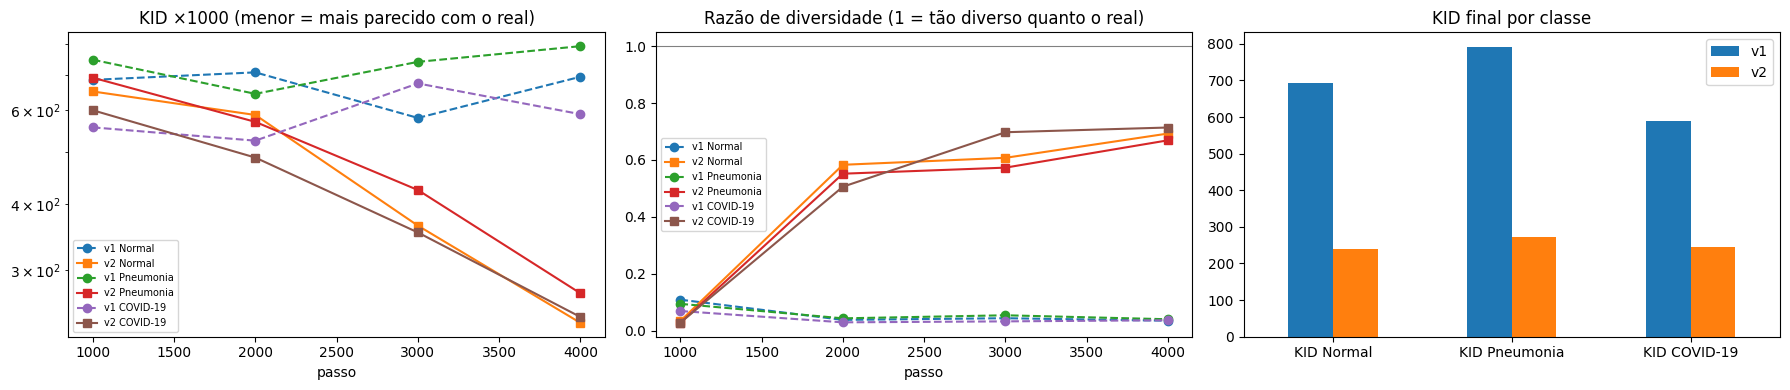

In [10]:
def smooth(s, k=5): return s.rolling(k, min_periods=1).mean()

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for r, v in enumerate(["v1", "v2"]):
    L = gan[v]["log"]
    axes[r, 0].plot(L.step, smooth(L.d_loss), label="loss D"); axes[r, 0].plot(L.step, smooth(L.g_loss), label="loss G")
    axes[r, 0].set_title(f"{v}: losses"); axes[r, 0].legend()
    axes[r, 1].plot(L.step, smooth(L.d_real), label="D(real) no batch"); axes[r, 1].plot(L.step, smooth(L.d_fake), label="D(falsa) no batch")
    axes[r, 1].set_title(f"{v}: saída do discriminador (logits)"); axes[r, 1].legend()
    axes[r, 2].plot(L.step, smooth(L.d_train_real), label="D(real de treino)"); axes[r, 2].plot(L.step, smooth(L.d_val_real), label="D(real de validação)")
    axes[r, 2].plot(L.step, smooth(L.overfit_gap), "k--", label="gap (overfitting do D)")
    axes[r, 2].set_title(f"{v}: o D decora o treino?"); axes[r, 2].legend()
    for a in axes[r]: a.set_xlabel("passo")
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_gan_diagnostico.png", dpi=130); plt.show()

ev = pd.concat([gan[v]["evals"].assign(versão=v) for v in ["v1", "v2"]])
display(ev.set_index(["versão", "step"]).round(3))
ev.to_csv(OUT_DIR / "a4_gan_metricas.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for c in range(NC):
    for v, st in [("v1", "o--"), ("v2", "s-")]:
        E = gan[v]["evals"]
        axes[0].plot(E.step, E[f"KID {CLASSES[c]}"], st, label=f"{v} {CLASSES[c]}")
        axes[1].plot(E.step, E[f"diversidade {CLASSES[c]}"], st, label=f"{v} {CLASSES[c]}")
axes[0].set_title("KID ×1000 (menor = mais parecido com o real)"); axes[0].set_yscale("log")
axes[1].set_title("Razão de diversidade (1 = tão diverso quanto o real)"); axes[1].axhline(1, color="gray", lw=0.8)
for a in axes[:2]: a.set_xlabel("passo"); a.legend(fontsize=7)
fin = pd.DataFrame({v: gan[v]["evals"].iloc[-1] for v in ["v1", "v2"]}).drop("step")
fin.loc[[f"KID {c}" for c in CLASSES]].plot.bar(ax=axes[2]); axes[2].set_title("KID final por classe"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_gan_metricas.png", dpi=130); plt.show()

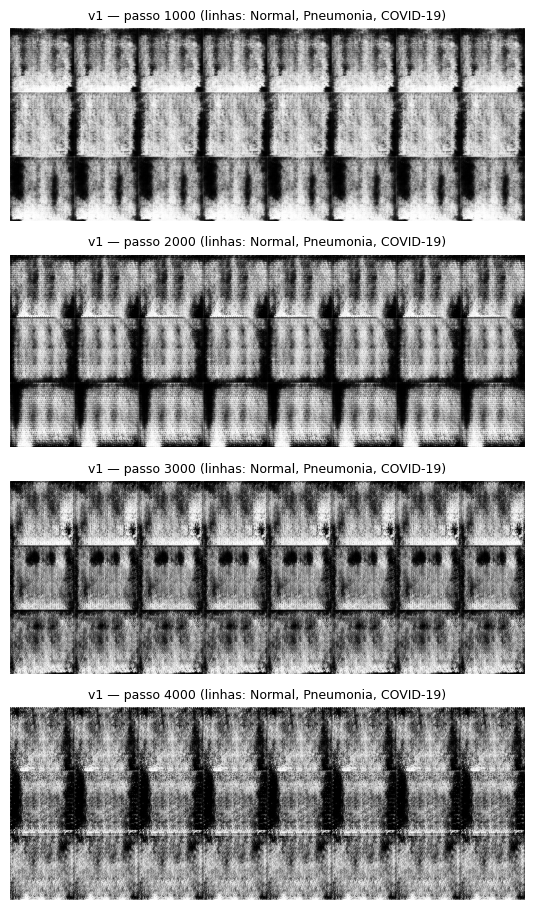

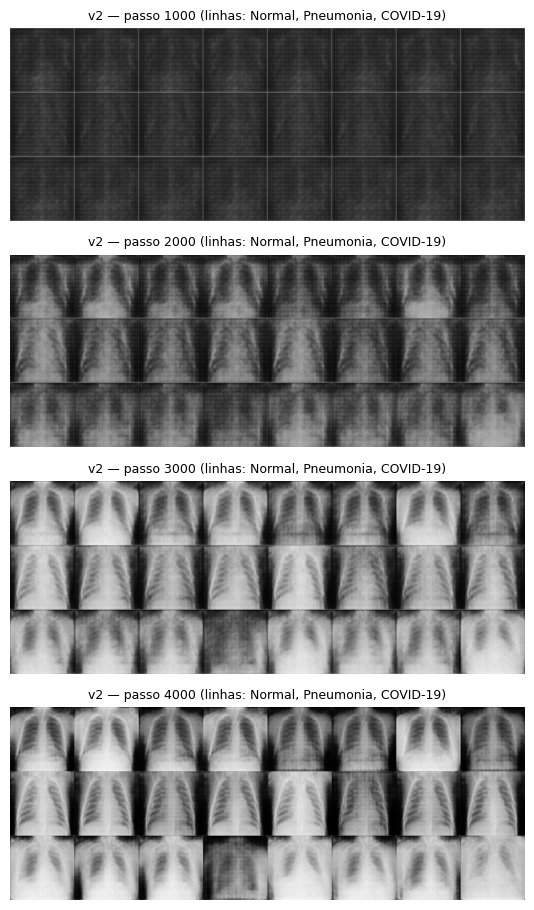

In [11]:
# Evolução visual: grade fixa (mesmo z) em cada avaliação, 8 amostras por classe
for v in ["v1", "v2"]:
    steps = sorted(gan[v]["snaps"])
    fig, axes = plt.subplots(len(steps), 1, figsize=(16, 2.3 * len(steps)))
    for ax, s in zip(np.atleast_1d(axes), steps):
        imgs = gan[v]["snaps"][s]                                  # (24, 1, 128, 128): 8 Normal, 8 Pneumonia, 8 COVID
        grid = torch.cat([torch.cat(list(imgs[c * 8:(c + 1) * 8, 0]), 1) for c in range(NC)], 0)
        ax.imshow(grid.numpy(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
        ax.set_title(f"{v} — passo {s} (linhas: Normal, Pneumonia, COVID-19)", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"a4_gan_{v}_evolucao.png", dpi=110); plt.show()


### Leitura do diagnóstico

**v1 (DCGAN clássica): mode collapse completo e discriminador dominante.**
- **Mode collapse visível:** nas grades de evolução, as 8 amostras de cada classe são praticamente **idênticas entre si** em todos os checkpoints, apesar de virem de 8 vetores de ruído diferentes. Pior, as três classes convergem para o mesmo padrão: o gerador passou a ignorar tanto o ruído quanto o rótulo. A razão de diversidade confirma: **0,03 a 0,11** em todas as classes e checkpoints, contra 1,0 do real.
- **Discriminador vence o jogo:** a loss do D cai para ~0,01 e fica lá, e a loss do G dispara (até ~41 no passo 2.000). Os logits do D ficam saturados, com ~+40 para reais e ~−20 para falsas. Com a BCE saturada, o gradiente que chega ao gerador carrega pouca informação útil.
- **Métricas não melhoram:** o KID de COVID oscila entre 526 e 674 sem tendência de queda, e as imagens pioram visualmente do passo 1.000 ao 4.000, com padrões de xadrez e manchas.
- **Gap de overfitting do D:** oscila muito (de −12 a +14), sem tendência clara. Com logits nessa escala, a medida fica ruidosa. Aqui a falha dominante foi saturação e collapse, mais do que memorização do treino.

**v2 (estabilizada): convergência e diversidade.**
- **Equilíbrio:** a loss do D fica entre 1,6 e 1,9 (na hinge, ~2 é o ponto em que o D não separa reais de falsas) e os logits ficam na faixa de ±0,5. O gap de overfitting fica entre −0,15 e +0,25: **o D não decorou o treino**, e é para isso que o DiffAugment foi incluído.
- **KID de COVID cai a cada avaliação:** 600 → 489 → 354 → **245**. A razão de diversidade sobe de 0,03 para 0,51, 0,70 e **0,71**. Nas outras classes: KID Normal 651 → 239 e KID Pneumonia 691 → 272.
- **O ponto baixo do passo 1.000 não é collapse.** É efeito da EMA: com decaimento de 0,999, a média móvel tem memória de ~1.000 passos e, nesse ponto, ainda é dominada pelos pesos iniciais, por isso as amostras são quase uniformes e escuras.
- **O treino não saturou:** o KID ainda caía no passo 4.000, então mais passos provavelmente melhorariam as imagens. Não estendi o treino por causa do tempo, já que cada GAN leva ~24 minutos na T4.

**Evidência de melhoria, v1 → v2 no passo 4.000:** KID de COVID de 590 para 245 (−58%), diversidade de COVID de 0,04 para 0,71, e o mesmo em Normal (KID 694 → 239) e Pneumonia (792 → 272).

**Qualidade das imagens da v2.** As sintéticas têm anatomia plausível: campos pulmonares, silhueta cardíaca, costelas e diafragma. Mas são borradas, têm um padrão fino de xadrez típico de convolução transposta e menos variação de enquadramento que as reais. Uma das 8 amostras de COVID na grade é uma imagem escura e quase vazia, um modo degenerado que ainda sobrevive.

**Limitação do experimento:** a v2 muda cinco coisas ao mesmo tempo (loss, spectral norm, DiffAugment, TTUR e EMA). O resultado mostra que o **conjunto** estabiliza, mas não isola a contribuição de cada técnica; uma ablação exigiria ~5 treinos adicionais de ~24 minutos cada.

**Sinal do problema 7 nas próprias imagens.** Na grade de reais, as radiografias de Pneumonia têm tórax estreito e proporções que parecem pediátricas, diferentes de Normal e COVID. Várias imagens de COVID trazem marcadores, letras e eletrodos. Isso é consistente com o que se sabe desse tipo de repositório: cada classe vem de fontes diferentes. Um classificador pode separar as classes por "criança vs. adulto" ou "tem marcador" sem olhar para a doença.


Gerador escolhido: v2, passo 4000 (KID COVID-19 = 245.26)


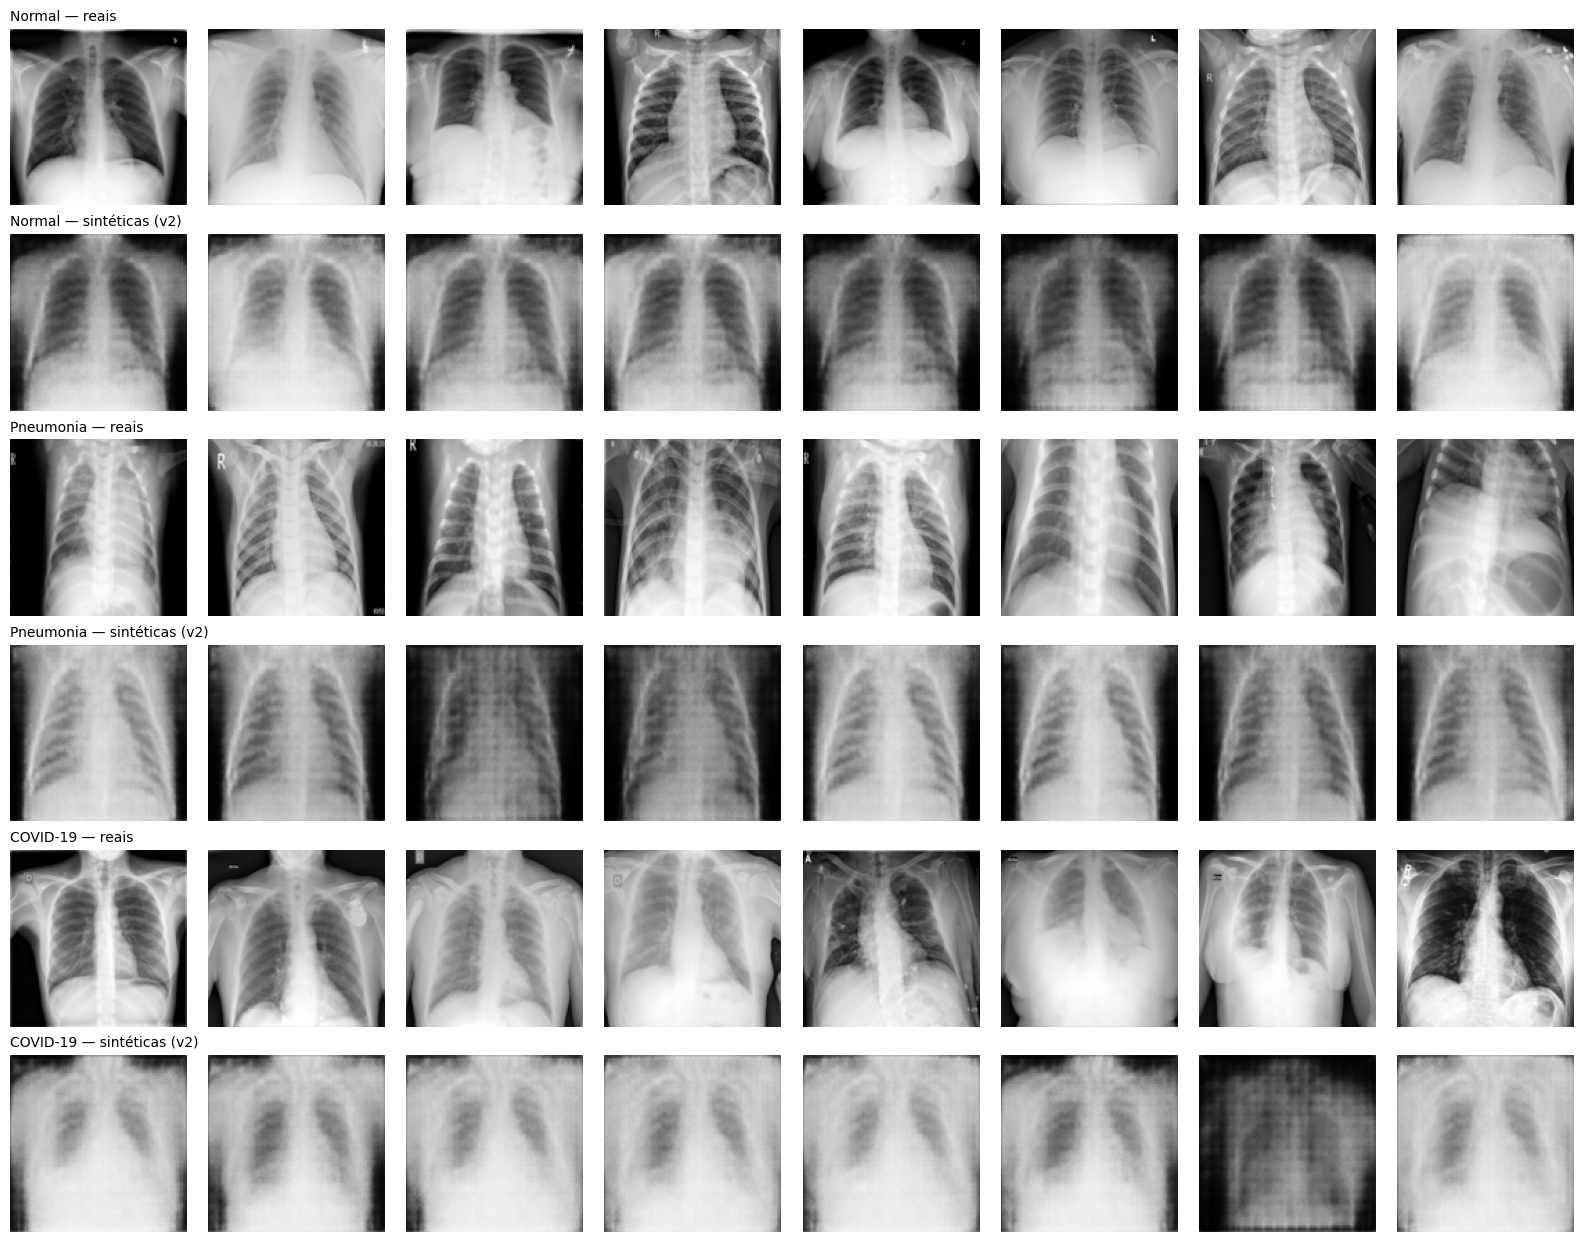

In [12]:
# Escolha do gerador para a augmentation: v2, no checkpoint com menor KID de COVID-19
E = gan["v2"]["evals"]
best_step = int(E.loc[E["KID COVID-19"].idxmin(), "step"])
G_final = Generator().to(DEVICE); G_final.load_state_dict(gan["v2"]["ckpts"][best_step]); G_final.eval()
print(f"Gerador escolhido: v2, passo {best_step} (KID COVID-19 = {E['KID COVID-19'].min():.2f})")

# Comparação visual: reais x sintéticas por classe
fig, axes = plt.subplots(6, 8, figsize=(16, 12.5))
for c in range(NC):
    reais = X_tr[y_tr == c][:8, 0]; sint = generate(G_final, 8, c, seed=100 + c)[:, 0]
    for j in range(8):
        axes[2 * c, j].imshow(reais[j], cmap="gray"); axes[2 * c + 1, j].imshow(sint[j], cmap="gray", vmin=0, vmax=1)
        axes[2 * c, j].axis("off"); axes[2 * c + 1, j].axis("off")
    axes[2 * c, 0].set_title(f"{CLASSES[c]} — reais", loc="left", fontsize=10)
    axes[2 * c + 1, 0].set_title(f"{CLASSES[c]} — sintéticas (v2)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_reais_vs_sinteticas.png", dpi=110); plt.show()

Similaridade com a vizinha mais próxima no treino — sintéticas: mediana 0.727, máx 0.782 | COVID reais de validação: mediana 0.836, máx 0.879


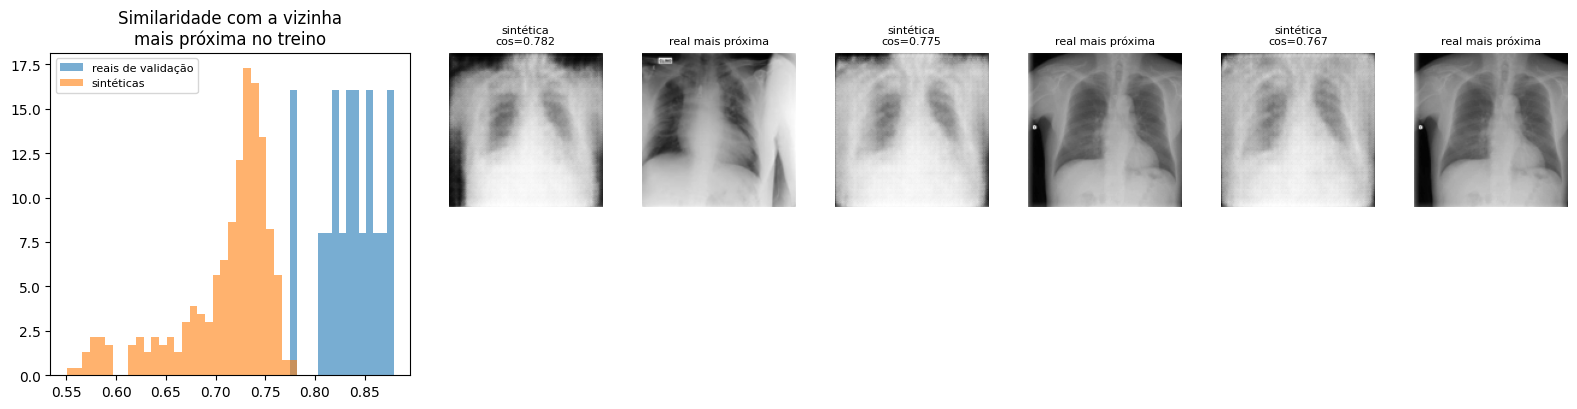

In [13]:
# Checagem de memorização: as COVID sintéticas são cópias das ~100 COVID de treino?
# Comparo a similaridade de cada imagem com a sua vizinha mais próxima no treino, para sintéticas e para COVID reais de validação.
syn_feats = incep_features(generate(G_final, 300, 2, seed=999))
va_covid_feats = incep_features(X_va[y_va == 2].float() / 255)
tr_n = F.normalize(REAL_FEATS[2], dim=1)
nn_syn = (F.normalize(syn_feats, dim=1) @ tr_n.T).max(1)
nn_val = (F.normalize(va_covid_feats, dim=1) @ tr_n.T).max(1).values
print(f"Similaridade com a vizinha mais próxima no treino — sintéticas: mediana {nn_syn.values.median():.3f}, máx {nn_syn.values.max():.3f} | "
      f"COVID reais de validação: mediana {nn_val.median():.3f}, máx {nn_val.max():.3f}")

fig = plt.figure(figsize=(16, 4.2))
ax = fig.add_subplot(1, 4, 1)
ax.hist(nn_val.numpy(), bins=15, alpha=.6, density=True, label="reais de validação"); ax.hist(nn_syn.values.numpy(), bins=30, alpha=.6, density=True, label="sintéticas")
ax.set_title("Similaridade com a vizinha\nmais próxima no treino"); ax.legend(fontsize=8)
syn_imgs = generate(G_final, 300, 2, seed=999)
top = nn_syn.values.argsort(descending=True)[:3]            # as 3 sintéticas MAIS parecidas com alguma real
tr_covid = X_tr[y_tr == 2]
for k, i in enumerate(top.tolist()):
    ax = fig.add_subplot(2, 8, 3 + 2 * k); ax.imshow(syn_imgs[i, 0], cmap="gray"); ax.axis("off"); ax.set_title(f"sintética\ncos={nn_syn.values[i]:.3f}", fontsize=8)
    ax = fig.add_subplot(2, 8, 4 + 2 * k); ax.imshow(tr_covid[nn_syn.indices[i], 0], cmap="gray"); ax.axis("off"); ax.set_title("real mais próxima", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_memorizacao.png", dpi=120); plt.show()


**Leitura da checagem de memorização.** A similaridade de cada COVID sintética com a vizinha mais próxima no treino tem mediana **0,727** (máximo 0,782). Para COVID reais de validação, que o modelo nunca viu, a mediana é **0,836** (máximo 0,879). As sintéticas estão **mais longe** do treino do que imagens reais novas, então **não há sinal de memorização**: a GAN não está devolvendo cópias das 102 radiografias de COVID.

O outro lado do mesmo número: as sintéticas também estão mais longe da distribuição real do que uma radiografia real qualquer, o que é coerente com o KID ainda alto (245) e com o aspecto borrado. Elas trazem variação nova, mas uma variação que não é exatamente a das radiografias reais.


## 5. Impacto na recall de COVID-19: com vs. sem imagens sintéticas

Treino a mesma receita corrigida (seção 3) em três configurações, com **3 sementes cada**. Com ~18 casos de COVID na validação, uma única execução poderia mostrar uma diferença que é só ruído.

| Configuração | Dados de treino | O que isola |
|---|---|---|
| **A. Só reais** | 1.020 reais (714 / 204 / 102) | linha de base da receita corrigida |
| **B. Reais + reamostragem** | mesmas 1.020, com `WeightedRandomSampler` balanceando as classes | a alternativa clássica e barata ao desbalanceamento |
| **C. Reais + 400 COVID sintéticas** | 1.420 (714 / 204 / 102 reais + 400 sintéticas) | **o efeito da augmentation por GAN** |

Todas são avaliadas no **mesmo teste externo** (1.400 / 400 / 200), que nenhum modelo nem a GAN viu. A validação continua só com imagens reais: não faria sentido escolher o modelo com base em imagens sintéticas.

In [14]:
N_SYN = 400
X_syn = (generate(G_final, N_SYN, 2, seed=2024) * 255).round().clamp(0, 255).to(torch.uint8)
X_tr_syn = torch.cat([X_tr, X_syn]); y_tr_syn = torch.cat([y_tr, torch.full((N_SYN,), 2)])
print("Treino com sintéticas:", {CLASSES[c]: int((y_tr_syn == c).sum()) for c in range(3)})

CONFIGS = {
    "A. Só reais":                 dict(X=X_tr, y=y_tr, balanced_sampler=False),
    "B. Reais + reamostragem":     dict(X=X_tr, y=y_tr, balanced_sampler=True),
    "C. Reais + COVID sintéticas": dict(X=X_tr_syn, y=y_tr_syn, balanced_sampler=False),
}
SEEDS = [0, 1, 2]
results, models_seed0, t0 = [], {}, time.time()
for name, cfg in CONFIGS.items():
    for s in SEEDS:
        m, h = train_classifier(cfg["X"], cfg["y"], X_va, y_va, balanced_sampler=cfg["balanced_sampler"], seed=s, tag=name)
        pt = predict(m, X_test); mt = metrics(y_test, pt)
        results.append({"config": name, "seed": s, **{k: v for k, v in mt.items() if k != "cm"}, "cm": mt["cm"]})
        if s == 0: models_seed0[name] = (m, pt, h)
print(f"Tempo total: {(time.time()-t0)/60:.1f} min")

res = pd.DataFrame(results)
cols = ["recall_covid", "precision_covid", "f1_covid", "auc_covid", "recall_pneumonia", "recall_normal", "balanced_acc", "macro_f1", "accuracy"]
summary = res.groupby("config")[cols].agg(["mean", "std"])
orig_row = pd.DataFrame({(k, "mean"): [m_orig_test[k]] for k in cols}, index=["Réplica do projeto original"])
table = pd.concat([orig_row, summary]).round(3)
display(table)
table.to_csv(OUT_DIR / "a4_resultados_classificador.csv")
res.drop(columns="cm").to_csv(OUT_DIR / "a4_resultados_por_semente.csv", index=False)

Treino com sintéticas: {'Normal': 714, 'Pneumonia': 204, 'COVID-19': 502}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 133MB/s]
/tmp/ipykernel_649/851678184.py:76: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


[A. Só reais] seed 0 | treino acc 0.997 | val acc 0.972 | val bal.acc (melhor) 0.964


/tmp/ipykernel_649/851678184.py:76: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


[A. Só reais] seed 1 | treino acc 0.998 | val acc 0.972 | val bal.acc (melhor) 0.954


...

/tmp/ipykernel_649/851678184.py:76: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


[C. Reais + COVID sintéticas] seed 1 | treino acc 0.998 | val acc 0.978 | val bal.acc (melhor) 0.954


/tmp/ipykernel_649/851678184.py:76: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


[C. Reais + COVID sintéticas] seed 2 | treino acc 0.998 | val acc 0.950 | val bal.acc (melhor) 0.896
Tempo total: 4.4 min


,recall_covid,precision_covid,f1_covid,auc_covid,recall_pneumonia,recall_normal,balanced_acc,macro_f1,accuracy,recall_covid,precision_covid,f1_covid,auc_covid,recall_pneumonia,recall_normal,balanced_acc,macro_f1,accuracy
,mean,mean,mean,mean,mean,mean,mean,mean,mean,std,std,std,std,std,std,std,std,std
Réplica do projeto original,0.260,0.650,0.371,0.835,0.932,0.963,0.718,0.739,0.886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A. Só reais,0.822,0.933,0.871,0.986,0.935,0.980,0.912,0.928,0.955,0.052,0.069,0.005,0.004,0.043,0.024,0.022,0.004,0.005
B. Reais + reamostragem,0.807,0.944,0.869,0.987,0.979,0.978,0.921,0.934,0.961,0.038,0.024,0.023,0.002,0.010,0.007,0.011,0.008,0.003
C. Reais + COVID sintéticas,0.837,0.917,0.874,0.984,0.968,0.977,0.927,0.936,0.962,0.033,0.026,0.012,0.005,0.015,0.014,0.007,0.006,0.006


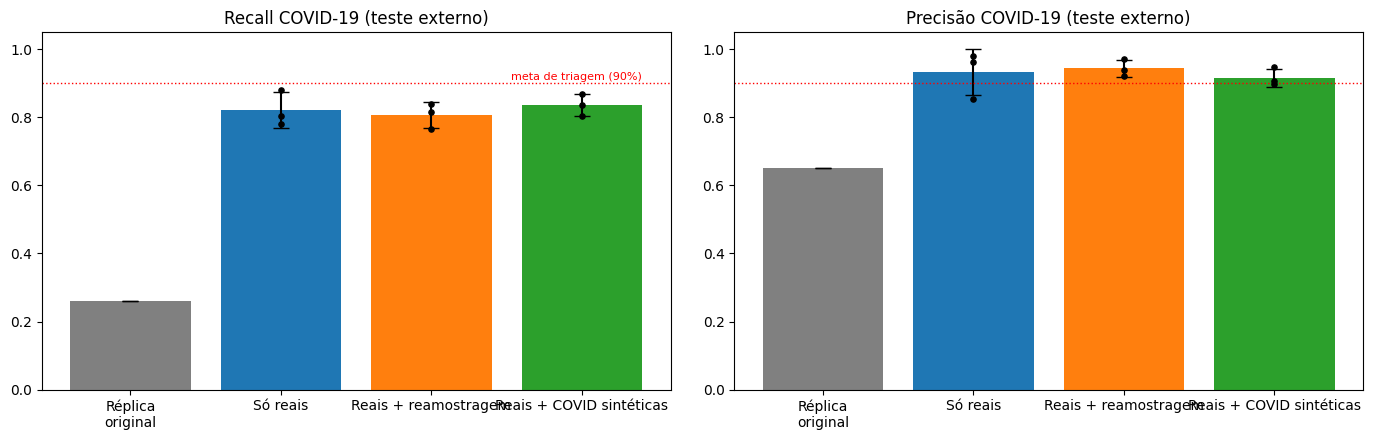

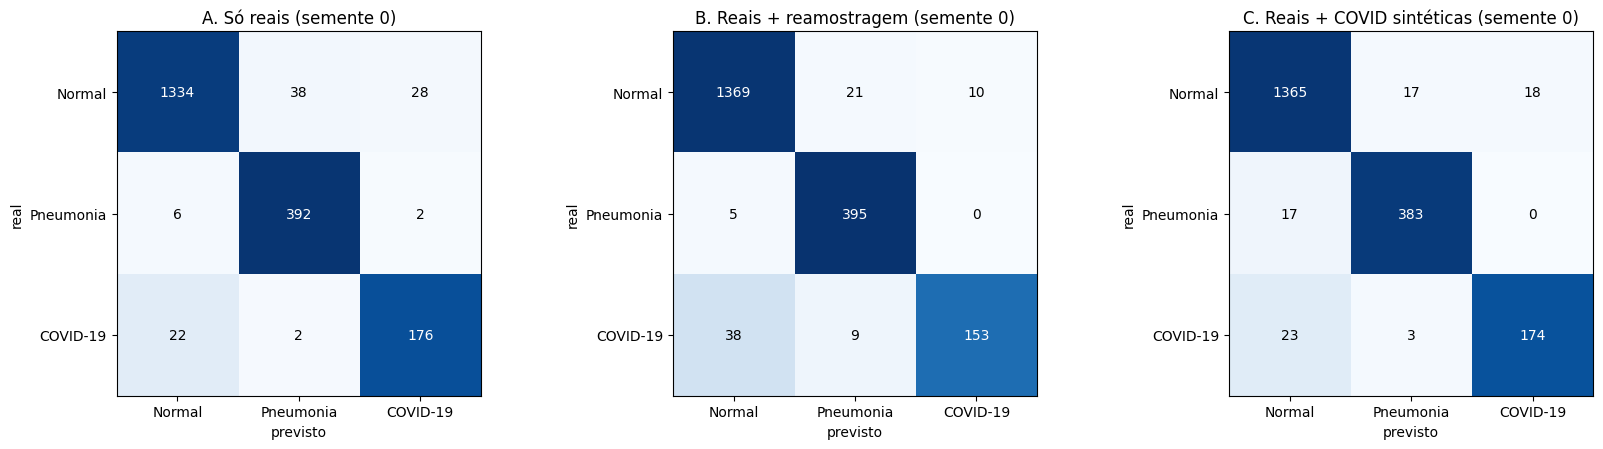

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = ["A. Só reais", "B. Reais + reamostragem", "C. Reais + COVID sintéticas"]
for k, (metric, title) in enumerate([("recall_covid", "Recall COVID-19 (teste externo)"), ("precision_covid", "Precisão COVID-19 (teste externo)")]):
    ax = axes[k]
    ax.bar(["Réplica\noriginal"] + [o.split(". ")[1] for o in order],
           [m_orig_test[metric]] + [res[res.config == o][metric].mean() for o in order],
           yerr=[0] + [res[res.config == o][metric].std() for o in order], capsize=6, color=["gray", "C0", "C1", "C2"])
    for i, o in enumerate(order):
        ax.scatter([i + 1] * len(SEEDS), res[res.config == o][metric], color="k", s=14, zorder=3)
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.axhline(0.9, color="red", ls=":", lw=1)
axes[0].text(3.4, 0.91, "meta de triagem (90%)", color="red", fontsize=8, ha="right")
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_recall_covid.png", dpi=140); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, o in zip(axes, order):
    cm = res[(res.config == o) & (res.seed == 0)].cm.iloc[0]
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] / cm[i].sum() > .5 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
    ax.set_title(f"{o} (semente 0)"); ax.set_xlabel("previsto"); ax.set_ylabel("real")
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_matrizes_confusao.png", dpi=130); plt.show()

### Ponto de operação: escolher o limiar pela sensibilidade

O argmax trata os três erros como equivalentes. Em triagem não são: deixar passar um COVID é pior do que mandar um paciente saudável para o exame confirmatório (RT-PCR). A prática correta é fixar uma **sensibilidade mínima** e aceitar a especificidade que vier. Escolho, **na validação**, o menor limiar de probabilidade de COVID que atinge recall ≥ 90%, e aplico esse limiar, sem mexer mais, no teste externo.

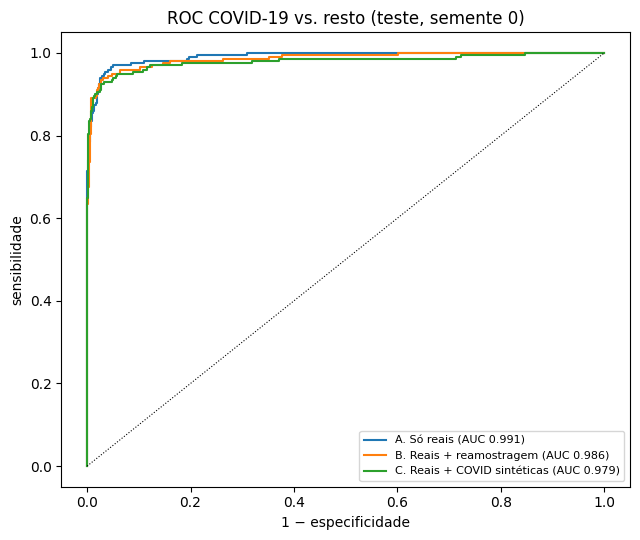

,limiar (validação),sensibilidade COVID,especificidade COVID,VPP (precisão)
config,,,,
A. Só reais,1.000,0.880,0.983,0.854
B. Reais + reamostragem,1.000,0.765,0.994,0.939
C. Reais + COVID sintéticas,0.169,0.930,0.965,0.747


In [16]:
def covid_rule(probs, t):
    pred = probs.argmax(1).clone(); pred[probs[:, 2] >= t] = 2
    return pred

rows = []
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for o in order:
    m, pt, _ = models_seed0[o]
    pv = predict(m, X_va)
    cand = np.sort(np.unique(pv[y_va == 2, 2].numpy()))[::-1]
    t = next((c for c in cand if ((covid_rule(pv, c) == 2) & (y_va == 2)).sum().item() / (y_va == 2).sum().item() >= 0.9), cand[-1])
    pred = covid_rule(pt, t)
    pos, neg = y_test == 2, y_test != 2
    rows.append({"config": o, "limiar (validação)": round(float(t), 4),
                 "sensibilidade COVID": ((pred == 2) & pos).sum().item() / pos.sum().item(),
                 "especificidade COVID": ((pred != 2) & neg).sum().item() / neg.sum().item(),
                 "VPP (precisão)": ((pred == 2) & pos).sum().item() / max((pred == 2).sum().item(), 1)})
    fpr, tpr, _ = roc_curve(pos.numpy().astype(int), pt[:, 2].numpy())
    ax.plot(fpr, tpr, label=f"{o} (AUC {roc_auc_score(pos.numpy().astype(int), pt[:, 2].numpy()):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("1 − especificidade"); ax.set_ylabel("sensibilidade"); ax.set_title("ROC COVID-19 vs. resto (teste, semente 0)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "a4_roc_covid.png", dpi=140); plt.show()
op = pd.DataFrame(rows).set_index("config").round(3); display(op); op.to_csv(OUT_DIR / "a4_ponto_operacao.csv")


### Leitura do experimento principal

| | Recall COVID | Precisão COVID | Recall Pneumonia | Balanced acc. | AUC COVID |
|---|---|---|---|---|---|
| Réplica do projeto original | 0,260 | 0,650 | 0,932 | 0,718 | 0,835 |
| A. Só reais | 0,822 ± 0,052 | 0,933 ± 0,069 | 0,935 ± 0,043 | 0,912 ± 0,022 | 0,986 |
| B. Reais + reamostragem | 0,807 ± 0,038 | 0,944 ± 0,024 | 0,979 ± 0,010 | 0,921 ± 0,011 | 0,987 |
| C. Reais + COVID sintéticas | **0,837 ± 0,033** | 0,917 ± 0,026 | 0,968 ± 0,015 | **0,927 ± 0,007** | 0,984 |

(média ± desvio entre 3 sementes, teste externo de 2.000 imagens)

**1. O maior ganho não vem da GAN, vem de corrigir a receita.** Só com transfer learning, augmentation adequada, divisão estratificada e seleção pela balanced accuracy, a recall de COVID sobe de **26% para 82%** (A). Nenhuma imagem sintética foi necessária para isso.

**2. O efeito das sintéticas é pequeno e não é distinguível do ruído.** C tem recall de COVID 1,5 ponto acima de A (0,837 contra 0,822), mas o desvio entre sementes de A é de 5,2 pontos. Com 3 sementes, essa diferença não é significativa. Em compensação, a precisão de COVID caiu 1,6 ponto (0,933 → 0,917), o esperado quando o modelo passa a chamar mais casos de COVID. O ganho mais consistente de C foi outro: a variação entre sementes ficou menor (balanced accuracy 0,927 ± 0,007 contra 0,912 ± 0,022) e a recall de Pneumonia subiu (0,935 → 0,968).

**3. Reamostragem não aumentou a recall de COVID.** B ficou em 0,807. O ganho de B foi na Pneumonia (0,979) e na precisão de COVID. Repetir as mesmas 102 imagens de COVID mais vezes não ensinou nada novo sobre COVID.

**4. Ponto de operação.** Com o limiar escolhido na validação para ≥ 90% de sensibilidade (semente 0):
- Em A e B, o argmax **já dava ≥ 90% na validação**, então o procedimento não baixou o limiar (o "1,000" da tabela significa "mantenha o argmax"). No teste, a sensibilidade foi de **88,0% em A** e **76,5% em B**. A queda de B de ≥ 90% na validação para 76,5% no teste mostra o limite de calibrar com **18 casos de COVID**: cada caso vale 5,6 pontos.
- Em C, o argmax não chegava a 90% na validação, e o limiar desceu para 0,169. No teste: **sensibilidade 93,0%, especificidade 96,5%, VPP 74,7%**. Foi a única configuração que passou de 90% de sensibilidade no teste, ao custo de mais falsos positivos (VPP de 85% em A para 75% em C).

**5. Decisão pelo critério definido no plano (seção 6.4).** O critério era: adotar as sintéticas só se melhorassem a sensibilidade de COVID **na validação**, de forma consistente entre sementes, e superassem a reamostragem. Na validação, a balanced accuracy de C por semente (0,946 / 0,954 / 0,896) ficou **abaixo** da de A (0,964 / 0,954 / 0,942). **Pelo critério, a augmentation por GAN não é adotada neste projeto.** O ganho visto no teste é pequeno demais para justificar os ~48 minutos de GAN e o risco de introduzir no treino imagens com artefatos (padrão de xadrez, amostras degeneradas).

**6. Onde a GAN poderia fazer diferença.** Com ~100 imagens de COVID e uma GAN que ainda não convergiu (KID caindo no passo 4.000), as sintéticas trazem variação nova, mas fora da distribuição real. Eu esperaria ganho maior com mais passos de treino, maior resolução, ou um modelo de difusão; e num cenário ainda mais escasso (20 a 30 casos de COVID), em que a receita corrigida sozinha não chegasse a 82%.

**Ressalva de validade:** o teste vem do mesmo repositório das imagens de treino. Não mede o problema 7 (fonte dos dados), e a seção 4 mostrou sinais de que ele existe aqui. Os números acima são um **limite superior** do que se veria num hospital novo.


## 6. Plano de melhoria integrado

O plano resolve os oito problemas da seção 1, organizado nos quatro eixos da atividade. Os números de referência vêm dos experimentos deste notebook.

### 6.1 Dados e protocolo de avaliação (problemas 3 e 7)
1. **Divisão por paciente e estratificada**, com três conjuntos: treino, validação (seleção de modelo e limiar) e teste congelado, usado uma única vez. Se houver mais de uma imagem por paciente, todas ficam no mesmo conjunto.
2. **Teste externo de outra instituição.** É a única forma de detectar shortcut learning por fonte de dados. Um ganho que só aparece no teste interno não conta.
3. **Auditoria de atalhos:** mapas de saliência (Grad-CAM) numa amostra de acertos e erros, checando se o modelo olha para o pulmão ou para bordas, marcadores de texto e dispositivos. Complementar com um teste em imagens com a região pulmonar mascarada: se o desempenho continuar alto sem o pulmão, o modelo está usando atalho.
4. **Tamanho mínimo de amostra de COVID no teste** para a sensibilidade ter intervalo de confiança útil: com 200 positivos, um IC de 95% tem cerca de ±5 pontos.

### 6.2 Modelo e treino (problemas 4, 5 e 6)
1. **Transfer learning** a partir de pesos pré-treinados. Idealmente de um modelo pré-treinado em radiografias (por exemplo, TorchXRayVision ou modelos auto-supervisionados em grandes bases de raio-X), que já conhece a anatomia torácica; o ImageNet é a alternativa mínima, e foi a usada aqui.
2. **Augmentation com critério clínico:** pequenas rotações e translações, variação de exposição e contraste, sem flip horizontal.
3. **Otimização:** AdamW com schedule (cosine ou OneCycle), seleção da época pela métrica clínica na validação e early stopping.
4. **Tratamento do desbalanceamento** com reamostragem ou pesos na loss, **combinado** com a augmentation sintética quando ela se mostrar útil (seção 6.4).
5. **Resolução:** 128 px foi uma restrição deste experimento, para casar com a GAN. Em produção, 224 a 512 px, porque opacidades sutis se perdem em resolução baixa.

### 6.3 Métrica e ponto de operação (problemas 1, 2 e 8)
1. **Métrica primária: sensibilidade (recall) de COVID-19**, reportada com intervalo de confiança. **Métricas secundárias obrigatórias:** especificidade, VPP e VPN na prevalência esperada, recall por classe, balanced accuracy, AUC e matriz de confusão. A accuracy global deixa de ser reportada como resultado principal.
2. **Limiar escolhido na validação** para uma sensibilidade-alvo, e não o argmax, e depois mantido fixo no teste.
3. **Calibração das probabilidades** (temperature scaling), para que "70% de chance de COVID" signifique de fato isso e o limiar seja estável entre versões do modelo.

### 6.4 Augmentation sintética com GAN
1. Usar a **GAN condicional estabilizada** (spectral norm, hinge, DiffAugment, TTUR, EMA): a versão base se mostrou instável com tão poucos dados.
2. **Gate de qualidade antes de usar as imagens:** KID por classe abaixo de um limite, razão de diversidade ≥ 0,8 e checagem de memorização (as sintéticas não podem estar mais próximas do treino do que imagens reais novas).
3. **Critério de adoção da própria augmentation:** as sintéticas só entram no pipeline se melhorarem a sensibilidade de COVID na **validação** de forma consistente entre sementes, sem perda relevante de especificidade, **e** superarem a alternativa barata (reamostragem). Caso contrário, ficam de fora. **Neste projeto, pelos resultados da seção 5, ficam de fora**: o ganho de recall (+1,5 ponto) ficou dentro da variação entre sementes e a validação não confirmou melhoria.
4. **Revisão por radiologista** de uma amostra das imagens sintéticas. Uma imagem que engana a métrica pode ter anatomia impossível, e o classificador aprenderia isso.
5. Em uma próxima versão, avaliar **modelos de difusão**, que hoje produzem radiografias sintéticas de mais qualidade e diversidade que GANs, com treino mais estável.

### 6.5 Critério de adoção clínica
O modelo só vai para uso, **como apoio à triagem e nunca como diagnóstico**, se cumprir todos os itens:

| Critério | Limite proposto |
|---|---|
| Sensibilidade COVID-19 no teste externo (outra instituição) | ≥ 90%, com limite inferior do IC 95% ≥ 85% |
| Especificidade COVID-19 no teste externo | ≥ 70% (os falsos positivos vão para RT-PCR, que é o exame confirmatório) |
| Recall de Pneumonia | ≥ 80% (pneumonia bacteriana ou viral também exige conduta) |
| Diferença de sensibilidade entre subgrupos (sexo, idade, aparelho, hospital) | ≤ 5 pontos |
| Auditoria de atalhos (Grad-CAM + teste com pulmão mascarado) | sem evidência de uso de marcadores, bordas ou texto |
| Estudo prospectivo silencioso | 4 a 8 semanas rodando em paralelo, sem influenciar condutas, com os mesmos critérios |
| Monitoramento pós-implantação | sensibilidade medida mensalmente contra o RT-PCR; queda de mais de 5 pontos dispara revisão |

O papel do modelo seria **priorizar a fila de laudos e o isolamento preventivo**, e não substituir o RT-PCR nem o radiologista. Nesse papel, um falso positivo custa um exame a mais; um falso negativo custa um paciente contagioso circulando. É por isso que toda a cadeia (métrica, limiar e critério) é construída em torno da sensibilidade.